# Dimensionality Reduction Comparison
This notebook compares different dimensionality reduction algorithms (t-SNE, MDS, LLE, UMAP, and our custom **NFMap**) on three datasets:
1. S-curve
2. Severed Sphere
3. Hand-written Digits

We use `matplotlib` and `seaborn` for clean visualizations.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ugtm import eGTM
from sklearn import datasets, manifold
from nfmap import NFMap

try:
    import umap
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False
    print("UMAP is not installed. It will be skipped in the comparison.")

sns.set_context('notebook')
sns.set_style('whitegrid')

In [ ]:
def plot_comparison(X, color, title):
    algorithms = {
        't-SNE': manifold.TSNE(n_components=2, init='pca', random_state=42),
        'MDS': manifold.MDS(n_components=2, max_iter=100, n_init=1, random_state=42),
        'LLE': manifold.LocallyLinearEmbedding(n_neighbors=20, n_components=2, method='standard', random_state=42),
        'NFMap': NFMap(n_components=2, use_canonical=False, random_state=42, graph_weight=5, complexity="low", sigma_perp=10, max_epochs=1000, patience=100),
        'GTM': eGTM()
    }
    if HAS_UMAP:
        algorithms['UMAP'] = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    
    # Make NFMap the last one for emphasis
    nfmap_algo = algorithms.pop('NFMap')
    algorithms['NFMap'] = nfmap_algo
    
    n_algos = len(algorithms)
    fig, axes = plt.subplots(1, n_algos, figsize=(5 * n_algos, 5))
    fig.suptitle(title, fontsize=16)
    
    for ax, (name, algo) in zip(axes, algorithms.items()):
        print(f'Fitting {name} on {title}...')
        try:
            Y = algo.fit_transform(X)
            scatter = ax.scatter(Y[:, 0], Y[:, 1], c=color, cmap=plt.cm.viridis, s=20, alpha=0.8)
            ax.set_title(name, fontsize=14, fontweight='bold' if name == 'NFMap' else 'normal')
            ax.axis('tight')
            ax.set_xticks([])
            ax.set_yticks([])
        except Exception as e:
            print(f'Error fitting {name}: {e}')
            ax.set_title(f'{name} (Failed)')
            
    plt.tight_layout()
    plt.show()

## 1. S-curve Dataset

Fitting t-SNE on S-curve Dataset...


Fitting MDS on S-curve Dataset...


Fitting LLE on S-curve Dataset...
Fitting GTM on S-curve Dataset...


Fitting UMAP on S-curve Dataset...


Fitting NFMap on S-curve Dataset...


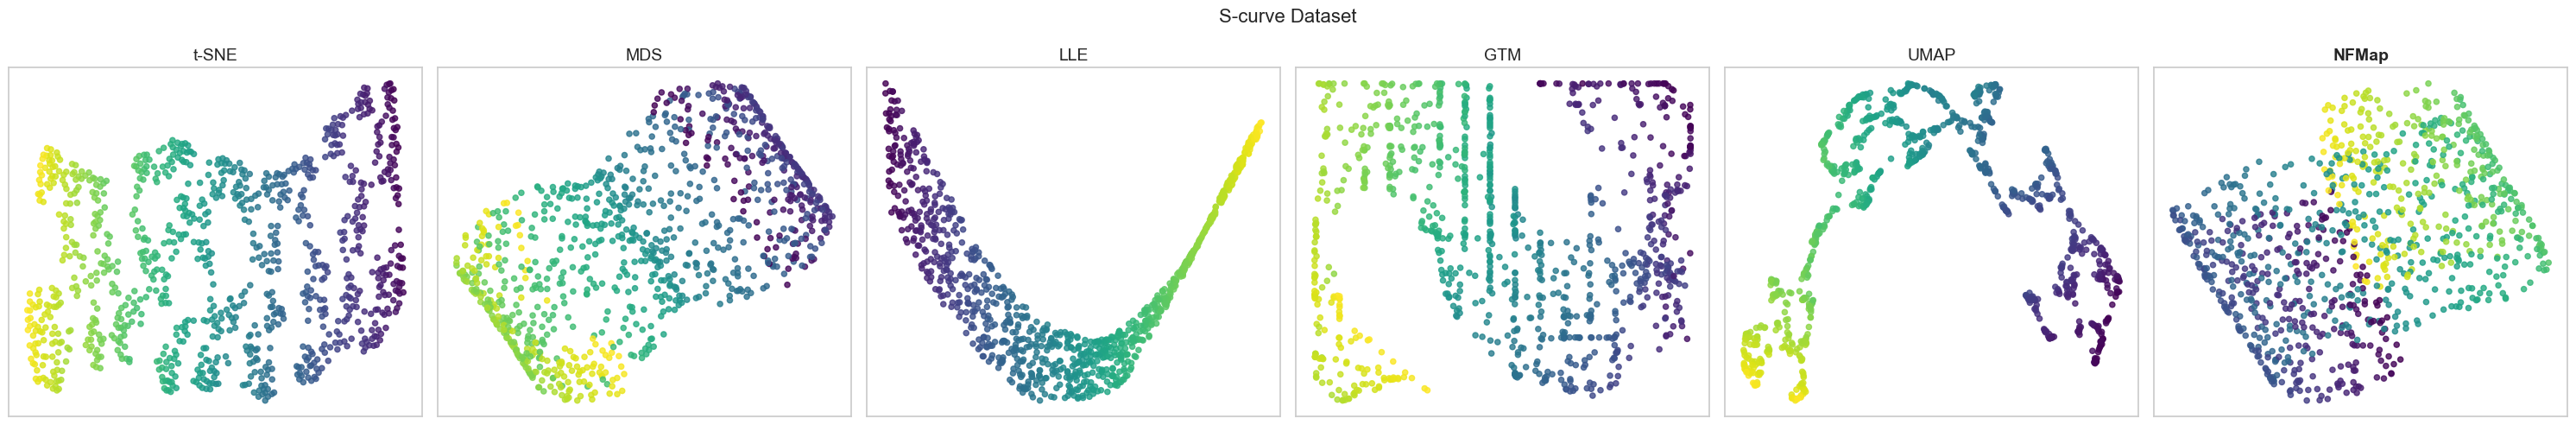

In [3]:
X_scurve, color_scurve = datasets.make_s_curve(n_samples=1000, random_state=42)
plot_comparison(X_scurve, color_scurve, 'S-curve Dataset')

## 1b. Swiss Roll Dataset

Fitting t-SNE on Swiss Roll Dataset...


Fitting MDS on Swiss Roll Dataset...


Fitting LLE on Swiss Roll Dataset...
Fitting GTM on Swiss Roll Dataset...


Fitting UMAP on Swiss Roll Dataset...


Fitting NFMap on Swiss Roll Dataset...


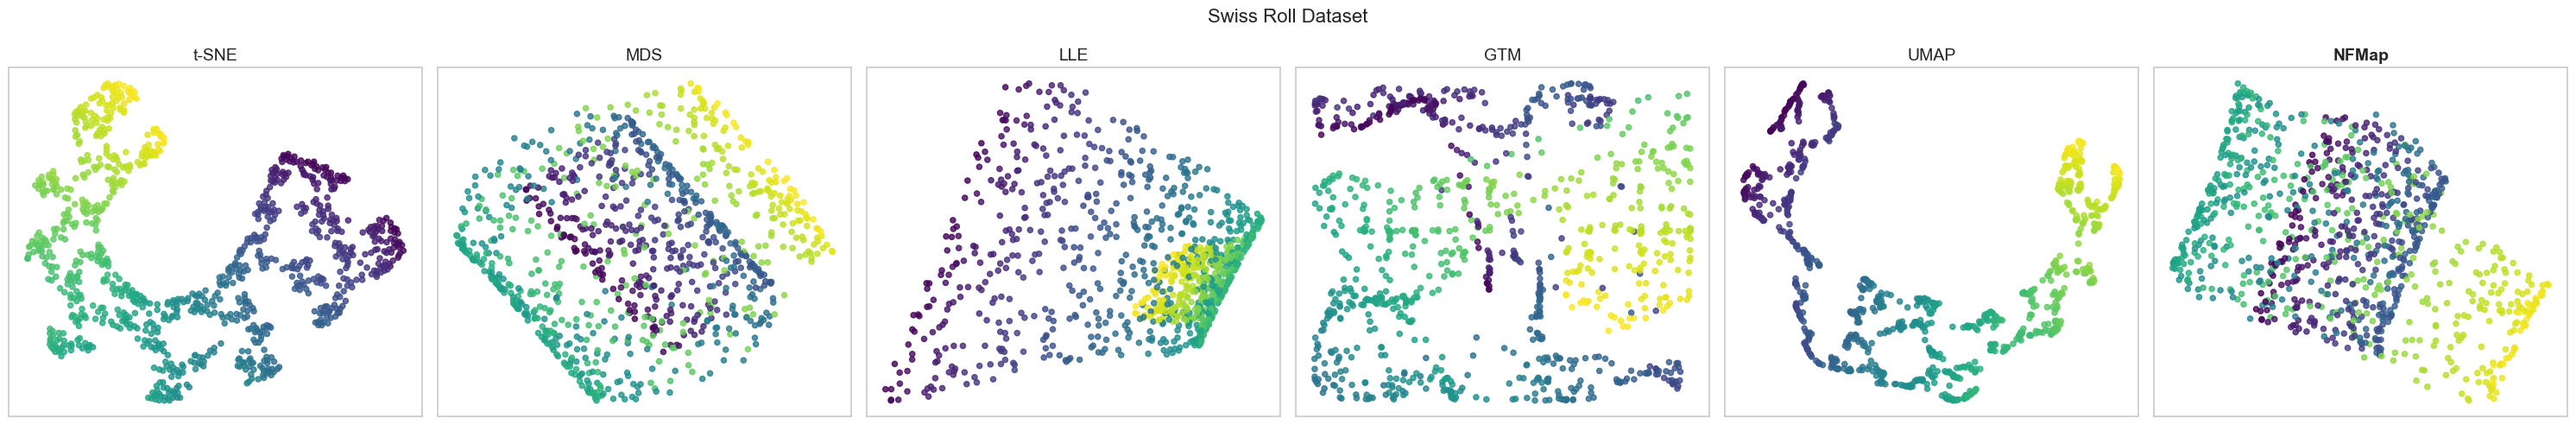

In [4]:
X_swiss, color_swiss = datasets.make_swiss_roll(n_samples=1000, random_state=42)
plot_comparison(X_swiss, color_swiss, 'Swiss Roll Dataset')

## 2. Severed Sphere Dataset

Fitting t-SNE on Severed Sphere Dataset...


Fitting MDS on Severed Sphere Dataset...


Fitting LLE on Severed Sphere Dataset...
Fitting GTM on Severed Sphere Dataset...


Fitting UMAP on Severed Sphere Dataset...


Fitting NFMap on Severed Sphere Dataset...


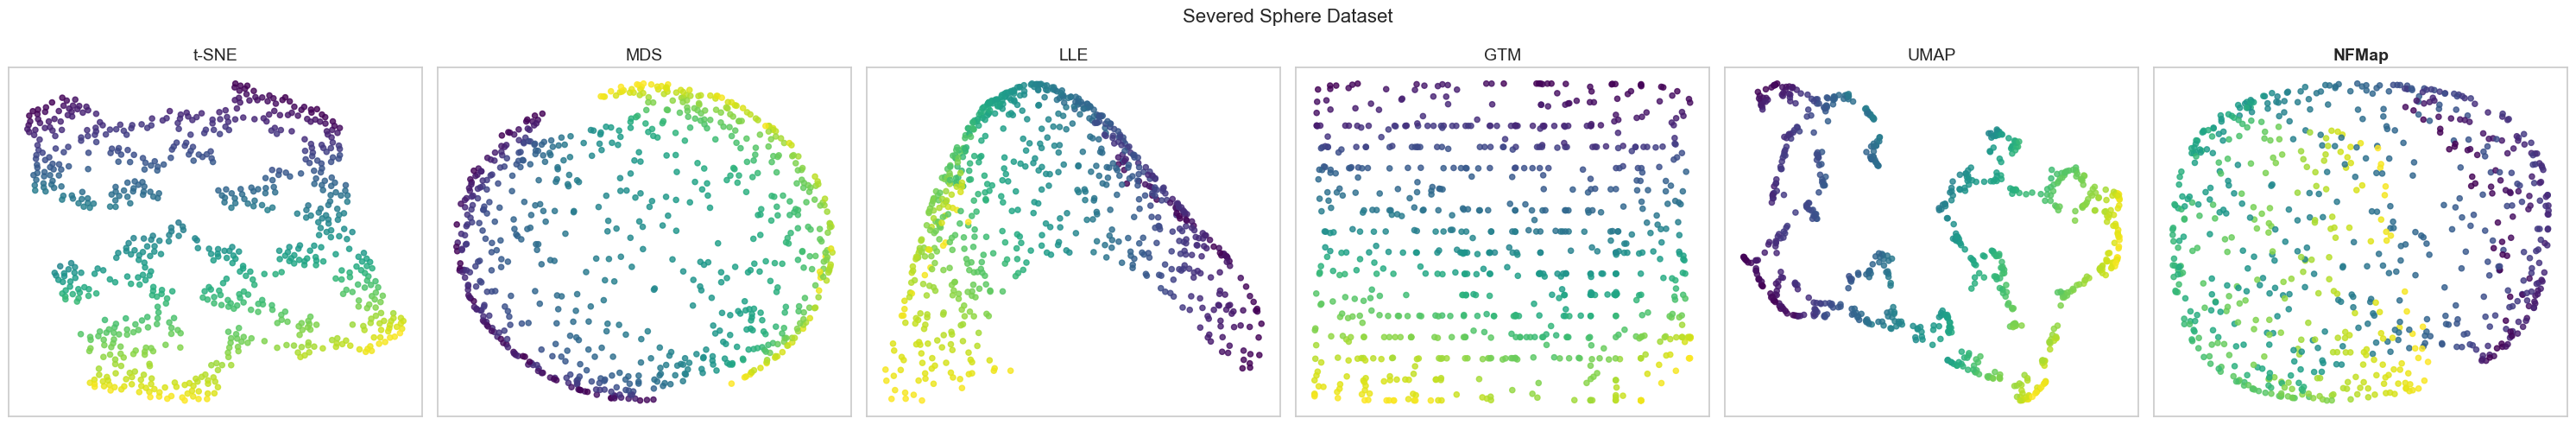

In [5]:
# Generate severed sphere
n_samples = 1000
np.random.seed(42)
p = np.random.rand(n_samples) * (2 * np.pi - 0.55)
t = np.random.rand(n_samples) * np.pi

# Sever the poles from the sphere
indices = (t < (np.pi - (np.pi / 8))) & (t > ((np.pi / 8)))
color_sphere = p[indices]
x, y, z = (
    np.sin(t[indices]) * np.cos(p[indices]),
    np.sin(t[indices]) * np.sin(p[indices]),
    np.cos(t[indices]),
)
X_sphere = np.array([x, y, z]).T

plot_comparison(X_sphere, color_sphere, 'Severed Sphere Dataset')

## 3. Hand-written Digits Dataset

Fitting t-SNE on Hand-written Digits (0-9)...


Fitting MDS on Hand-written Digits (0-9)...


Fitting LLE on Hand-written Digits (0-9)...


Fitting GTM on Hand-written Digits (0-9)...


Fitting UMAP on Hand-written Digits (0-9)...


Fitting NFMap on Hand-written Digits (0-9)...


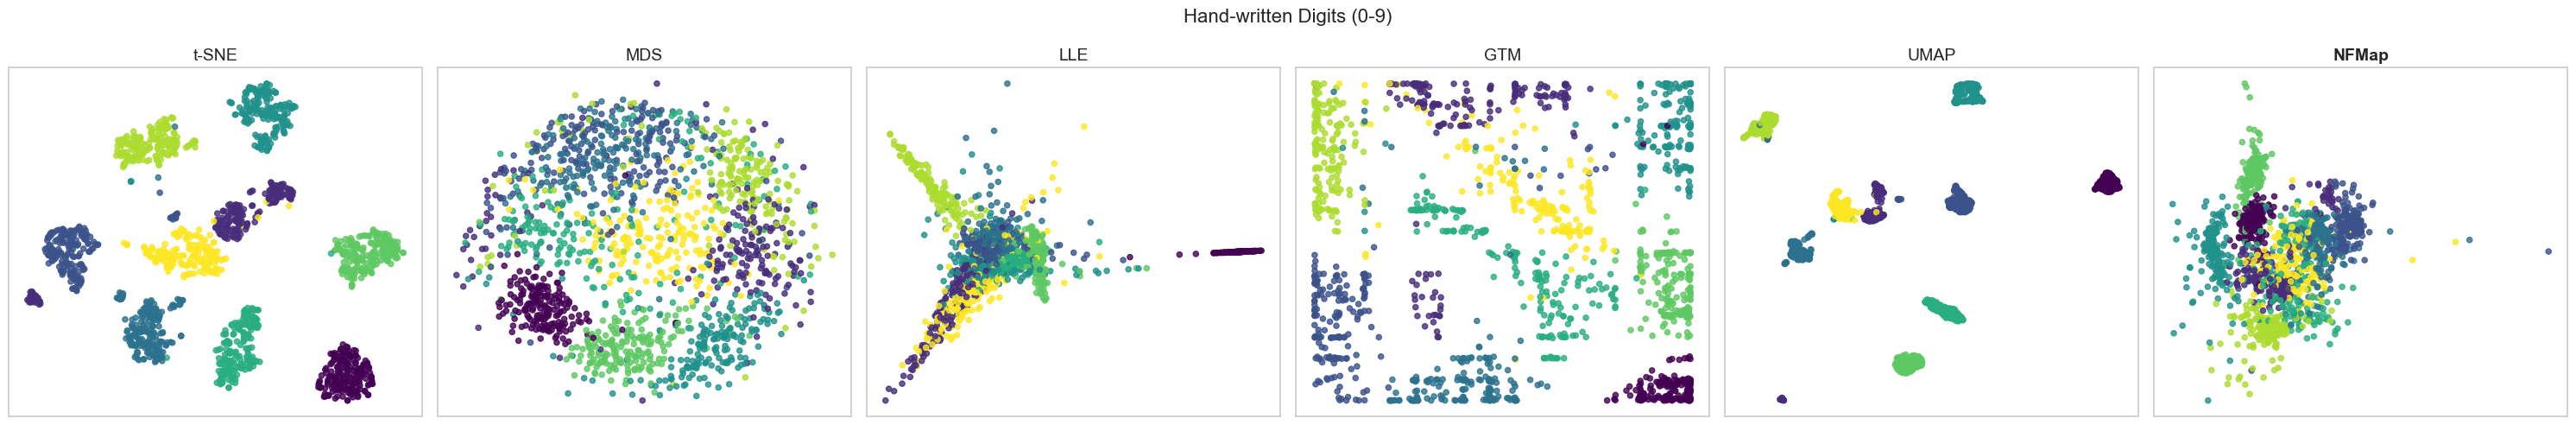

In [6]:
digits = datasets.load_digits(n_class=9)
X_digits = digits.data
color_digits = digits.target



plot_comparison(X_digits, color_digits, 'Hand-written Digits (0-9)')